<a href="https://colab.research.google.com/github/Bry312/Proyecto-Final/blob/main/Documento_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sismicidad en Costa Rica (2015-2025): distribución espacial por cantón y desarrollo de una aplicación web interactiva

**Autor:** Bryan Ramírez Coria

**Curso:** GF-0657 Programación en Sistemas de Información Geográfica, II-2026

**Proyecto final**

## Resumen

Este documento analiza la distribución espacial de los sismos de magnitud 3.0 o mayor registrados en Costa Rica y sus alrededores entre 2015 y 2025, y su relación con la división cantonal del país. Los datos provienen del catálogo del Servicio Geológico de los Estados Unidos (USGS), consultado directamente por su API, y de la capa de cantones del Instituto Geográfico Nacional (IGN). Los sismos se convierten en una capa de puntos con `geopandas` y se asignan a los cantones mediante una unión espacial (punto en polígono) en el sistema de referencia EPSG:8908 (CRTM05); los sismos que no caen dentro de ningún cantón se clasifican como marinos. Los resultados se presentan en tablas, gráficos de `matplotlib` y `plotly`, un mapa estático y un mapa web interactivo de `folium`.

El catálogo analizado incluye 528 sismos, 180 continentales (dentro de algún cantón) y 348 maritimos. La sismicidad continental se concentra en el extremo sur del Pacífico, en los cantones de Corredores, Golfito y Pérez Zeledón, una zona asociada a la colisión de la cordillera submarina de Coco con el margen continental. Los sismos marinos son más numerosos y, en promedio, más someros (profundidad media de 24,8 km frente a 37,4 km de los continentales), y la profundidad y la magnitud prácticamente no están correlacionadas (r = -0,03). Finalmente, este documento describe la aplicación web desarrollada en `streamlit` y publicada en Streamlit Community Cloud, que permite filtrar los datos y explorarlos en indicadores, gráficos, un mapa y una tabla.

## 1. Introducción

### Tema y relevancia

Costa Rica se ubica sobre el límite de las placas tectónicas, siendo la de Cocos, Caribe, Nazca y el bloque de Panamá. La subducción de la placa de Cocos bajo la placa Caribe, a lo largo de la Fosa Mesoamericana, es la principal responsable de que en el país se localicen entre 3 000 y 4 000 sismos cada año (Linkimer et al., 2024). Aunque la gran mayoría son de baja magnitud y no son sentidos por la población, el país ha sufrido eventos de gran impacto, como el terremoto de Cinchona (2009) y el de Sámara-Nicoya (2012). Conocer dónde se concentra la sismicidad, y en qué cantones, es relevante para la gestión del riesgo y la planificación del territorio, porque los cantones son la escala a la que se organizan la administración y la atención de emergencias.

### Preguntas del proyecto

1. ¿Dónde se concentran espacialmente los sismos de magnitud ≥ 3.0 registrados en Costa Rica entre 2015 y 2025?
2. ¿Cuántos sismos se han registrado en cada cantón y cuáles tienen mayor actividad sísmica?
3. ¿Qué relación existe entre la profundidad y la magnitud de los sismos, y existen diferencias entre los sismos continentales (dentro de algún cantón) y los marinos (fuera de todo cantón, asociados a la zona de subducción)?

### Fuentes de los datos

- **Sismos:** U.S. Geological Survey. (s. f.). *Earthquake Catalog* [conjunto de datos]. Servicio FDSN Event Web Service. https://earthquake.usgs.gov/earthquakes/search/. Se consulta por URL, filtrando por el rectángulo delimitador de Costa Rica, el período 2015-01-01 a 2025-12-31 y magnitud ≥ 3.0.
- **Cantones de Costa Rica:** Instituto Geográfico Nacional (IGN), publicada en el repositorio del curso GF-0657 Programación en SIG (2026-II). https://github.com/gf0657-programacionsig/2026-ii/blob/main/datos/ign/cantones.gpkg

### Descripción de las tablas y capas

| Capa | Geometría | SRC original | Variables principales |
|---|---|---|---|
| Sismos (USGS) | Puntos, construidos a partir de latitud y longitud | EPSG:4326 (WGS84) | `time`, `latitude`, `longitude`, `depth` (km), `mag`, `place` |
| Cantones (IGN) | Polígonos | EPSG:8908 (CRTM05) | `canton`, `provincia` |

## 2. Datos y métodos

In [1]:
try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    %pip install --quiet geopandas folium plotly


In [2]:
import importlib.metadata as metadatos

import branca.colormap as bcm
import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px

pd.set_option("display.max_columns", None)

# Bibliotecas usadas y sus versiones
bibliotecas = ["pandas", "geopandas", "matplotlib", "plotly", "folium", "branca"]
pd.DataFrame(
    {"Biblioteca": bibliotecas,
     "Versión": [metadatos.version(b) for b in bibliotecas]}
)


,Biblioteca,Versión
0,pandas,2.2.3
1,geopandas,1.2.0
2,matplotlib,3.10.0
3,plotly,5.24.1
4,folium,0.20.0
5,branca,0.8.2


### Carga de la capa de sismos

Se consulta el servicio FDSN Event Web Service del USGS directamente por URL. El resultado es una tabla CSV con columnas `latitude` y `longitude`, que se convierte en una capa de puntos con `geopandas.points_from_xy()`, en WGS84 (EPSG:4326), el sistema en el que el USGS reporta las coordenadas.

In [3]:
# Rectángulo delimitador aproximado de Costa Rica (incluye la zona marina
# donde ocurre buena parte de la sismicidad de subducción), 2015-2025, M >= 3.0
url_usgs = (
    "https://earthquake.usgs.gov/fdsnws/event/1/query?"
    "format=csv"
    "&starttime=2015-01-01"
    "&endtime=2025-12-31"
    "&minlatitude=8.0"
    "&maxlatitude=11.3"
    "&minlongitude=-86.5"
    "&maxlongitude=-82.5"
    "&minmagnitude=3.0"
    "&orderby=time"
)

sismos_df = pd.read_csv(url_usgs)
print(f"Sismos descargados: {len(sismos_df)}")
sismos_df.head()


Sismos descargados: 528


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2025-12-20T12:43:51.342Z,8.7445,-83.5964,36.540,4.1,mb,29.0,159.0,1.070,0.75,us,us7000rpmb,2026-03-19T13:56:07.040Z,"25 km SSW of Puerto Cortés, Costa Rica",earthquake,8.19,11.112,0.131,16.0,reviewed,us,us
1,2025-12-07T14:20:43.819Z,8.8276,-83.9370,10.000,4.4,mb,26.0,145.0,0.910,0.80,us,us6000rt5m,2026-03-04T18:42:54.040Z,"47 km WSW of Puerto Cortés, Costa Rica",earthquake,8.17,1.907,0.131,17.0,reviewed,us,us
2,2025-11-25T02:48:57.992Z,8.8225,-84.0746,10.000,4.3,mb,21.0,145.0,0.916,0.44,us,us7000rdlf,2026-02-20T16:07:41.040Z,"62 km WSW of Puerto Cortés, Costa Rica",earthquake,6.43,1.914,0.178,9.0,reviewed,us,us
3,2025-11-22T18:41:20.057Z,8.8416,-84.0883,10.998,5.1,mww,159.0,108.0,0.898,0.65,us,us6000rpvb,2026-02-20T16:07:34.040Z,"63 km WSW of Puerto Cortés, Costa Rica",earthquake,5.24,3.743,0.044,50.0,reviewed,us,us
4,2025-11-22T10:29:01.638Z,11.0286,-85.1706,218.702,4.5,mb,33.0,79.0,0.222,0.64,us,us6000rptb,2026-02-20T16:07:33.040Z,"9 km NNW of San José, Costa Rica",earthquake,9.28,2.886,0.057,90.0,reviewed,us,us


In [4]:
# Conversión de la tabla con coordenadas en una capa de puntos
sismos = gpd.GeoDataFrame(
    sismos_df,
    geometry=gpd.points_from_xy(sismos_df["longitude"], sismos_df["latitude"]),
    crs="EPSG:4326",
)

# Solo las columnas necesarias para el análisis
sismos = sismos[["time", "latitude", "longitude", "depth", "mag", "place", "geometry"]].copy()
sismos["time"] = pd.to_datetime(sismos["time"])

print(f"SRC de la capa de sismos: {sismos.crs}")
sismos.head()


SRC de la capa de sismos: EPSG:4326


,time,latitude,longitude,depth,mag,place,geometry
0,2025-12-20 12:43:51.342000+00:00,8.7445,-83.5964,36.540,4.1,"25 km SSW of Puerto Cortés, Costa Rica",POINT (-83.5964 8.7445)
1,2025-12-07 14:20:43.819000+00:00,8.8276,-83.9370,10.000,4.4,"47 km WSW of Puerto Cortés, Costa Rica",POINT (-83.937 8.8276)
2,2025-11-25 02:48:57.992000+00:00,8.8225,-84.0746,10.000,4.3,"62 km WSW of Puerto Cortés, Costa Rica",POINT (-84.0746 8.8225)
3,2025-11-22 18:41:20.057000+00:00,8.8416,-84.0883,10.998,5.1,"63 km WSW of Puerto Cortés, Costa Rica",POINT (-84.0883 8.8416)
4,2025-11-22 10:29:01.638000+00:00,11.0286,-85.1706,218.702,4.5,"9 km NNW of San José, Costa Rica",POINT (-85.1706 11.0286)


### Carga de la capa de cantones

La capa de cantones del IGN se carga desde la URL del repositorio del curso. Ya está en EPSG:8908 (CRTM05), el sistema de referencia oficial de Costa Rica, proyectado y en metros.

In [5]:
url_cantones = (
    "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/"
    "main/datos/ign/cantones.gpkg"
)

cantones = gpd.read_file(url_cantones)

# Nombres de las columnas de cantón y provincia en la capa
COL_CANTON = "canton"
COL_PROVINCIA = "provincia"

print(f"SRC de la capa de cantones: {cantones.crs}")
print(f"Cantones: {len(cantones)}")
cantones[[COL_CANTON, COL_PROVINCIA, "geometry"]].head()


SRC de la capa de cantones: EPSG:8908
Cantones: 84


,canton,provincia,geometry
0,San José,San José,"MULTIPOLYGON (((481030.294 1102633.121, 481510..."
1,Escazú,San José,"MULTIPOLYGON (((479844.884 1102669.54, 479982...."
2,Desamparados,San José,"MULTIPOLYGON (((494091.189 1094936.765, 494448..."
3,Puriscal,San José,"MULTIPOLYGON (((455732.107 1095962.406, 456519..."
4,Tarrazú,San José,"MULTIPOLYGON (((501118.557 1074475.546, 502323..."


### Reproyección y operación espacial

**Reproyección.** Para relacionar las dos capas, ambas deben estar en el mismo sistema de referencia. Los sismos se reproyectan de EPSG:4326 al EPSG:8908 (CRTM05) de los cantones, un sistema proyectado adecuado para Costa Rica.

**Unión espacial (punto en polígono).** Con `gpd.sjoin()` y el predicado `within`, en EPSG:8908, se determina el cantón en que ocurrió cada sismo. Esta operación responde a las preguntas 1 y 2 (¿dónde? y ¿cuántos por cantón?). Los sismos que no caen dentro de ningún cantón, es decir, los que ocurren en el mar, quedan sin cantón asignado y se clasifican como **marinos**, en lugar de forzarlos dentro de un cantón; el resto se clasifica como **continental**.

In [6]:
# Reproyección de los sismos al SRC de los cantones
sismos_8908 = sismos.to_crs(cantones.crs)

# Unión espacial: cantón en el que ocurrió cada sismo (SRC: EPSG:8908)
sismos_canton = gpd.sjoin(
    sismos_8908,
    cantones[[COL_CANTON, COL_PROVINCIA, "geometry"]],
    how="left",
    predicate="within",
)

# Tipo de sismo: continental (dentro de un cantón) o marino (fuera de todo cantón)
sismos_canton["tipo"] = sismos_canton[COL_CANTON].notna().map(
    {True: "Continental", False: "Marino"}
)

sismos_con_canton = sismos_canton[sismos_canton["tipo"] == "Continental"].copy()
sismos_sin_canton = sismos_canton[sismos_canton["tipo"] == "Marino"].copy()

print(f"Sismos continentales: {len(sismos_con_canton)}")
print(f"Sismos marinos: {len(sismos_sin_canton)}")


Sismos continentales: 180
Sismos marinos: 348


## 3. Resultados

### 3.1 Sismos por cantón (tabla)

La tabla muestra el número de sismos continentales (M ≥ 3.0, 2015-2025) por cantón, ordenados de mayor a menor. Los sismos marinos no pertenecen a ningún cantón y se analizan en la sección 3.4.

In [7]:
conteo_canton = (
    sismos_con_canton
    .groupby([COL_CANTON, COL_PROVINCIA])
    .size()
    .reset_index(name="numero_sismos")
    .sort_values("numero_sismos", ascending=False)
    .reset_index(drop=True)
)

print(f"Cantones con al menos un sismo: {len(conteo_canton)} de {len(cantones)}")

# Los 15 cantones con más sismos
conteo_canton.head(15).style.format({"numero_sismos": "{:,.0f}"}).background_gradient(
    subset=["numero_sismos"], cmap="Purples"
)


Cantones con al menos un sismo: 51 de 84


,canton,provincia,numero_sismos
0,Corredores,Puntarenas,21
1,Golfito,Puntarenas,17
2,Pérez Zeledón,San José,14
3,Quepos,Puntarenas,8
4,Upala,Alajuela,8
5,Puriscal,San José,7
6,Santa Cruz,Guanacaste,7
7,Guatuso,Alajuela,7
8,Coto Brus,Puntarenas,6
9,Buenos Aires,Puntarenas,5


La actividad sísmica continental no se distribuye de forma homogénea entre los cantones: unos pocos concentran la mayor parte de los eventos registrados en tierra, y varios cantones no registraron ningún sismo de magnitud ≥ 3.0 en el período.

### 3.2 Cantones con mayor actividad sísmica (gráfico)

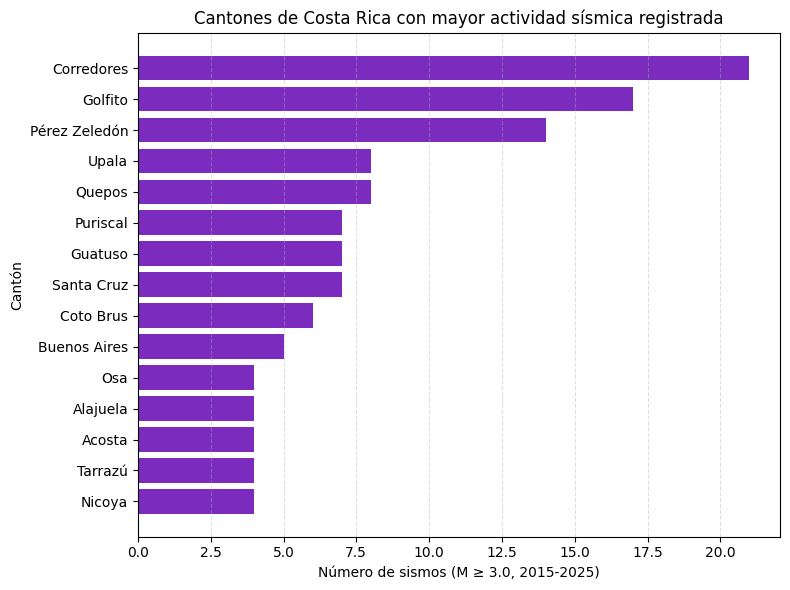

In [8]:
top15 = conteo_canton.head(15).sort_values("numero_sismos")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top15[COL_CANTON], top15["numero_sismos"], color="#7b2cbf")
ax.set_xlabel("Número de sismos (M ≥ 3.0, 2015-2025)")
ax.set_ylabel("Cantón")
ax.set_title("Cantones de Costa Rica con mayor actividad sísmica registrada")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


**Interpretación:** tres cantones se separan claramente del resto: **Corredores** (alrededor de 20 sismos), **Golfito** (alrededor de 17) y **Pérez Zeledón** (alrededor de 14). Los tres se ubican en el extremo sur del Pacífico costarricense, en torno a la península de Osa, una zona asociada a la colisión de la cordillera submarina de Coco con el margen continental y reconocida por su alta sismicidad. Un segundo grupo, de entre 5 y 8 sismos (Upala, Quepos, Puriscal, Guatuso, Santa Cruz y Coto Brus), mezcla cantones del Pacífico Norte y de la zona norte, y el resto de los 15 primeros se agrupa alrededor de 4 sismos cada uno.

### 3.3 Mapas

#### Mapa estático: sismos por cantón

Mapa de coropletas, en EPSG:8908, con el número de sismos continentales por cantón. Los cantones sin ningún sismo registrado se muestran en gris.

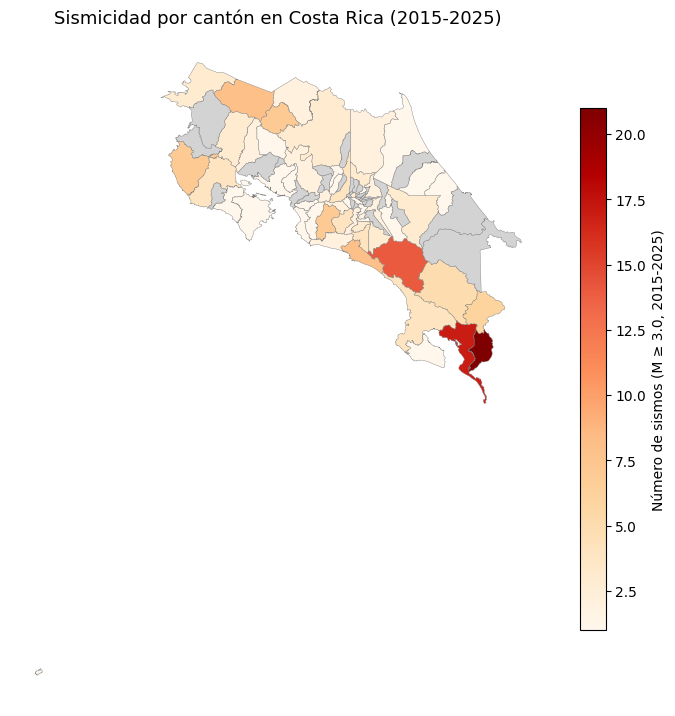

In [9]:
# Unión del conteo con la capa completa de cantones; los cantones sin sismos
# quedan sin valor (NaN) y se dibujan en gris
cantones_mapa = cantones[[COL_CANTON, COL_PROVINCIA, "geometry"]].merge(
    conteo_canton, on=[COL_CANTON, COL_PROVINCIA], how="left"
)

fig, ax = plt.subplots(figsize=(7, 9))
cantones_mapa.plot(
    column="numero_sismos",
    cmap="OrRd",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin sismos registrados"},
    legend_kwds={"label": "Número de sismos (M ≥ 3.0, 2015-2025)", "shrink": 0.6},
    ax=ax,
)
ax.set_title("Sismicidad por cantón en Costa Rica (2015-2025)", fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.show()


**Interpretación:** los tonos más oscuros se concentran en el extremo sur de la provincia de Puntarenas (Corredores y Golfito) y se extienden hacia Pérez Zeledón. Los cantones en gris, sin ningún sismo de magnitud ≥ 3.0 en el período, se agrupan sobre todo en la vertiente Caribe y el norte del país, más alejados del frente de subducción del Pacífico. El resto del territorio muestra tonos intermedios o claros, es decir, actividad presente pero mucho menos concentrada que en el extremo sur.

#### Mapa web interactivo

Mapa con `folium` con una capa base y tres capas con nombre: los cantones, coloreados según el número de sismos, y los sismos continentales y marinos como puntos, con etiquetas emergentes y leyenda. Las capas se reproyectan a WGS84 (EPSG:4326), el sistema que requiere `folium`. Como capa base se usa la de Esri, que no requiere llave de API.

In [10]:
# Capas en WGS84 para el mapa web
cantones_web = cantones_mapa.copy()
cantones_web["numero_sismos"] = cantones_web["numero_sismos"].fillna(0).astype(int)
cantones_web = cantones_web.to_crs("EPSG:4326")
sismos_web = sismos_canton.to_crs("EPSG:4326")

vmax = max(int(cantones_web["numero_sismos"].max()), 1)
escala = bcm.LinearColormap(
    ["#fff5eb", "#fdae6b", "#e6550d", "#7f0000"],
    vmin=0,
    vmax=vmax,
    caption="Número de sismos por cantón (M ≥ 3.0, 2015-2025)",
)

def estilo(feature):
    n = feature["properties"]["numero_sismos"]
    return {
        "fillColor": "#e0e0e0" if n == 0 else escala(n),
        "color": "#555555",
        "weight": 0.5,
        "fillOpacity": 0.7,
    }

m = folium.Map(location=[9.7489, -83.7534], zoom_start=8, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri — World Street Map",
    name="Mapa base",
).add_to(m)

# Capa 1: cantones coloreados por número de sismos
folium.GeoJson(
    cantones_web,
    name="Cantones (sismos por cantón)",
    style_function=estilo,
    tooltip=folium.GeoJsonTooltip(
        fields=[COL_CANTON, COL_PROVINCIA, "numero_sismos"],
        aliases=["Cantón:", "Provincia:", "N.° de sismos:"],
    ),
).add_to(m)
escala.add_to(m)

# Capas 2 y 3: sismos continentales y marinos
grupos = {
    "Continental": ("Sismos continentales", "#d9480f"),
    "Marino": ("Sismos marinos", "#1c7ed6"),
}
for tipo_sismo, (nombre, color) in grupos.items():
    capa = folium.FeatureGroup(name=nombre)
    for fila in sismos_web[sismos_web["tipo"] == tipo_sismo].itertuples():
        canton = getattr(fila, COL_CANTON)
        canton = "Fuera de cantón (mar)" if pd.isna(canton) else canton
        folium.CircleMarker(
            location=[fila.geometry.y, fila.geometry.x],
            radius=2 + fila.mag,
            color="#2b2b2b",
            weight=0.5,
            fill=True,
            fill_color=color,
            fill_opacity=0.7,
            popup=folium.Popup(
                f"<b>Fecha:</b> {fila.time:%Y-%m-%d %H:%M}<br>"
                f"<b>Magnitud:</b> {fila.mag:.1f}<br>"
                f"<b>Profundidad:</b> {fila.depth:.1f} km<br>"
                f"<b>Cantón:</b> {canton}<br>"
                f"<b>Lugar (USGS):</b> {fila.place}",
                max_width=260,
            ),
        ).add_to(capa)
    capa.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m


**Interpretación:** el mapa interactivo muestra algo que el mapa estático por cantón no puede mostrar: la franja de sismos ocurridos en el mar, frente a la costa del Pacífico, asociada a la Fosa Mesoamericana y a la subducción de la placa de Cocos, que queda fuera de los límites de cualquier cantón. Al explorar los puntos se distingue además que el grupo más denso de sismos se ubica en el extremo sur de Puntarenas (Corredores-Golfito), lo que es coherente con el conteo por cantón de la tabla y el gráfico.

### 3.4 Profundidad y magnitud: sismos continentales y marinos

Tabla comparativa de la profundidad y la magnitud de los sismos continentales y marinos, y gráfico de dispersión interactivo de `plotly` con las dos variables.

In [11]:
tabla_prof_mag = pd.DataFrame(
    {
        "Grupo": ["Continental", "Marino"],
        "N": [len(sismos_con_canton), len(sismos_sin_canton)],
        "Profundidad media (km)": [
            sismos_con_canton["depth"].mean(), sismos_sin_canton["depth"].mean()
        ],
        "Profundidad mediana (km)": [
            sismos_con_canton["depth"].median(), sismos_sin_canton["depth"].median()
        ],
        "Magnitud media": [
            sismos_con_canton["mag"].mean(), sismos_sin_canton["mag"].mean()
        ],
        "Magnitud máxima": [
            sismos_con_canton["mag"].max(), sismos_sin_canton["mag"].max()
        ],
    }
).round(2)

tabla_prof_mag


,Grupo,N,Profundidad media (km),Profundidad mediana (km),Magnitud media,Magnitud máxima
0,Continental,180,37.41,18.93,4.39,6.1
1,Marino,348,24.76,17.92,4.53,6.5


In [12]:
# Correlación (Pearson) entre profundidad y magnitud, para todos los sismos
correlacion = sismos_canton[["depth", "mag"]].corr().iloc[0, 1]
print(f"Correlación entre profundidad y magnitud: {correlacion:.2f}")

fig = px.scatter(
    pd.DataFrame(sismos_canton.drop(columns="geometry")),
    x="mag",
    y="depth",
    color="tipo",
    color_discrete_map={"Continental": "#7b2cbf", "Marino": "#2a9d8f"},
    opacity=0.7,
    labels={
        "mag": "Magnitud",
        "depth": "Profundidad (km)",
        "tipo": "Tipo de sismo",
    },
    title="Profundidad vs. magnitud de los sismos en Costa Rica (2015-2025)",
)
fig.update_yaxes(autorange="reversed")  # los sismos más someros arriba
fig.show()


Correlación entre profundidad y magnitud: -0.03


**Interpretación:** los sismos continentales (N = 180) tienen una profundidad media de 37,4 km (mediana de 18,9 km) y una magnitud media de 4,39, con un máximo de 6,1. Los marinos (N = 348, casi el doble) son en promedio más someros, con profundidad media de 24,8 km (mediana de 17,9 km), y una magnitud media algo mayor, de 4,53, con un máximo de 6,5. En el gráfico, la mayoría de los sismos de ambos grupos se agrupa entre 0 y 50 km de profundidad y entre magnitudes 4,0 y 4,5. La diferencia principal está en los eventos profundos: casi todos los de más de 100 km son continentales, y los marinos rara vez superan los 150 km, lo que es coherente con la subducción de la placa de Cocos, que se hunde bajo el margen continental. El coeficiente de correlación (r = -0,03) indica que la profundidad y la magnitud son prácticamente independientes: los sismos de mayor magnitud aparecen tanto muy someros como a profundidad intermedia.

## 4. La aplicación web

### Enlaces

- **Aplicación publicada:** [https://proyecto-final-bryan.streamlit.app/](https://proyecto-final-bryan.streamlit.app/)
- **Repositorio:** [Link del repositorio](https://bry312.github.io/Proyecto-Final/)

### Estructura de la aplicación

La aplicación (`app.py`) reúne en una sola página las tablas, gráficos y mapas de este análisis, con controles que filtran los datos:

- **Qué carga:** los sismos del catálogo del USGS (consultados por URL) y la capa de cantones del IGN (repositorio del curso), en funciones con `@st.cache_data`. La unión espacial se hace al cargar los datos, en EPSG:8908, y las capas del mapa se reproyectan a WGS84.
- **Qué controles tiene:** cinco filtros en la barra lateral: rango de años, magnitud mínima, profundidad máxima, provincia y tipo de sismo (todos, continentales o marinos). Todos los elementos de la página responden a los mismos filtros, y si ningún sismo cumple los filtros se muestra un mensaje de advertencia.
- **Qué muestra:** cuatro indicadores (número de sismos, magnitud máxima, profundidad media y porcentaje de sismos continentales) y tres pestañas: un mapa interactivo (cantones coloreados por número de sismos y los sismos continentales y marinos como capas independientes), dos gráficos de `plotly` (cantones con más sismos, y profundidad vs. magnitud) y una tabla de los sismos de la selección, con descarga en CSV.

### Captura de pantalla

`![Captura de la aplicación](https://github.com/Bry312/Proyecto-Final/blob/main/Captura_Proyecto_Final.png)`]

### Decisiones de diseño

- **Los mismos filtros para todo:** el conteo por cantón, los gráficos, la tabla y el mapa se calculan siempre a partir de la misma selección, para que muestren los mismos sismos.
- **Sismos marinos como categoría propia:** como una parte importante de la sismicidad ocurre fuera de los límites cantonales, los sismos marinos se mantienen en el análisis como una categoría separada, en lugar de excluirlos o asignarlos a un cantón. Por eso, al elegir una provincia, la aplicación solo muestra sismos continentales.
- **Mapa:** se construye en una función con `@st.cache_resource` cuyos argumentos son los valores de los filtros, y se dibuja una copia (`copy.deepcopy()`) para que conserve la vista entre clics.
- **Capa base de Esri:** se eligió por no requerir cuenta ni llave de API (ver el siguiente apartado).

### Problemas encontrados y soluciones

| Problema | Solución |
|---|---|
| El mapa base de `folium` (CartoDB Positron) mostraba el mensaje "API KEY REQUIRED", y la capa de OpenStreetMap devolvía un error 403 por la política de uso de sus servidores. | Se usó la capa de Esri por URL, como `TileLayer` con nombre ("Mapa base"), que es gratuita y no requiere llave. |
| El control de capas mostraba la dirección de la capa base en lugar de un nombre. | Se creó el mapa con `tiles=None` y se agregó la capa base aparte con `folium.TileLayer(..., name="Mapa base")`. |
| Al ejecutar `app.py` con el botón de ejecución de VS Code salía `ModuleNotFoundError: No module named 'branca'`. | VS Code usaba otro Python, y no el ambiente `geopython`. Se seleccionó el intérprete correcto y la aplicación se ejecutó con `python -m streamlit run app.py` en lugar de ejecutar el archivo como un script. |
| PowerShell bloqueaba la activación del ambiente de conda por la política de ejecución de scripts. | Se cambió la política de ejecución del usuario (`Set-ExecutionPolicy -Scope CurrentUser RemoteSigned`) y se abrió una terminal nueva. |
| Un error de sintaxis (`SyntaxError`) tras pegar el código de la tabla con colores. | Se reemplazó completo el bloque de la pestaña de la tabla, en lugar de pegar fragmentos sobre el código existente. |
| La vista previa del cuaderno en GitHub no mostraba el mapa interactivo ("Make this Notebook Trusted"). | El visor de GitHub no ejecuta JavaScript; los mapas web se ven al abrir el cuaderno en Colab. |
| La publicación en Streamlit Community Cloud exige las versiones de las bibliotecas. | Se generó el `requirements.txt` con las versiones del ambiente local con `importlib.metadata`. |

## 5. Conclusiones

1. **¿Dónde se concentran los sismos?** Los sismos de magnitud ≥ 3.0 registrados entre 2015 y 2025 se concentran principalmente en el extremo sur de Puntarenas y en el cantón de Pérez Zeledón, en la zona donde la cordillera submarina de Coco colisiona con el margen continental frente a la península de Osa. A esto se suma una franja importante de sismos marinos frente a la costa del Pacífico, asociada a la Fosa Mesoamericana, que queda fuera de los cantones y solo es visible en el mapa web interactivo.

2. **¿Cuántos sismos hay en cada cantón?** Los cantones con más sismos registrados fueron Corredores (alrededor de 20), Golfito (alrededor de 17) y Pérez Zeledón (alrededor de 14), muy por encima del resto. Un número considerable de cantones, sobre todo en la vertiente Caribe y la zona norte, no registraron ningún sismo de magnitud ≥ 3.0.

3. **Profundidad, magnitud y tipo de sismo:** la profundidad y la magnitud no muestran una relación lineal apreciable (r = -0,03). Los sismos marinos son más numerosos (348 frente a 180) y, en promedio, más someros (24,8 km frente a 37,4 km), mientras que casi todos los eventos de más de 100 km de profundidad son continentales, como se espera por la subducción de la placa de Cocos bajo el territorio.

4. **Aplicación:** la aplicación web permite explorar estos mismos resultados de forma interactiva, filtrando por años, magnitud, profundidad, provincia y tipo de sismo, con indicadores, gráficos, mapa y tabla que responden a una misma selección.

### Limitaciones

- El análisis se restringe a sismos de magnitud ≥ 3.0, lo que excluye la gran mayoría de la sismicidad diaria del país, de menor magnitud.
- La asignación de un sismo a un cantón con `within` depende de la precisión de las coordenadas del USGS y de la resolución de la capa de cantones; los sismos muy cercanos a un límite pueden quedar en el cantón vecino.
- Los sismos marinos no se incluyen en el conteo por cantón, aunque son una parte importante de la sismicidad y del riesgo para las zonas costeras.
- El catálogo del USGS puede diferir del de las redes sismológicas nacionales (RSN y OVSICORI) en la cantidad de eventos y en las magnitudes, y se actualiza con revisiones posteriores, por lo que las cifras pueden variar ligeramente según la fecha de consulta.
- El período de 2015 a 2025 es corto frente a los ciclos sísmicos de las principales fallas, por lo que los patrones observados no constituyen una evaluación de peligro sísmico a largo plazo.

## 6. Referencias bibliográficas

- Esri. (s. f.). *World Street Map* [servicio de mapas base]. https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer
- GeoPandas developers. (s. f.). *GeoPandas documentation*. https://geopandas.org/
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55
- Instituto Geográfico Nacional (IGN). *Cantones de Costa Rica* [conjunto de datos]. Publicada en el repositorio del curso GF-0657 Programación en SIG (2026-II). https://github.com/gf0657-programacionsig/2026-ii/blob/main/datos/ign/cantones.gpkg
- Linkimer, L., Fallas, C. y Arroyo, I. G. (2024). Origen de los sismos sentidos en Costa Rica durante el año 2023. *Revista Geológica de América Central, 70*. https://revistas.ucr.ac.cr/index.php/geologica/article/view/58439
- Folium developers. (s. f.). *Folium documentation*. https://python-visualization.github.io/folium/
- pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/
- Plotly Technologies Inc. (s. f.). *Plotly Python graphing library*. https://plotly.com/python/
- Streamlit. (s. f.). *Streamlit documentation*. https://docs.streamlit.io/
- streamlit-folium developers. (s. f.). *streamlit-folium* [software]. https://github.com/randyzwitch/streamlit-folium
- U.S. Geological Survey. (s. f.). *Earthquake Catalog* [conjunto de datos]. Servicio FDSN Event Web Service. https://earthquake.usgs.gov/earthquakes/search/

## 7. Declaración de uso de asistentes de inteligencia artificial

Se utilizó el asistente Claude (Anthropic) comoayuda de orientación en la redacción de la primera versión de app.py (funciones de carga con caché, filtros, indicadores, tabla, gráficos de plotly y mapa con streamlit-folium). También fue de utilidad para resolver los problemas del mapa base de las tareas anteriores (las capas base de CartoDB y de OpenStreetMap exigían llave o bloqueaban el acceso, por lo que se usa la capa de Esri).

Declaro comprender el funcionamiento de todo el código entregado y estar en capacidad de explicarlo.
